# 03 · Linear & logistic regression with `nn`, and why feature scaling is not optional

Notebook 02 used bare tensors. Here you move to the real tools — `nn.Linear`, a loss object, `torch.optim` — on real-looking data, and you meet the first thing that goes wrong on real data: **features with large values make gradient descent blow up**.

---
## Theory in 60 seconds

- **Linear regression**: `ŷ = X w + b`, loss = MSE. In PyTorch: `nn.Linear(d, 1)` + `nn.MSELoss()`.
- **Logistic regression**: `p = σ(X w + b)`, loss = binary cross-entropy. In PyTorch: `nn.Linear(d, 1)` + `nn.BCEWithLogitsLoss()` (the sigmoid lives inside the loss).
- Both are a "network" with a single layer and no hidden units — the training loop is *identical* to that of an MLP.
- **Standardisation**: `x' = (x − mean) / std`, per column. Mean and std are computed on the **training** data and re-used unchanged for validation/test data.
- From 02: gradient of a weight = error × input. Large inputs → large gradients → the stable learning rate becomes tiny, and then the *other* parameters (e.g. the bias) barely move.

(1200,) 83.516174 29.184513 | 202.30649 89.15722


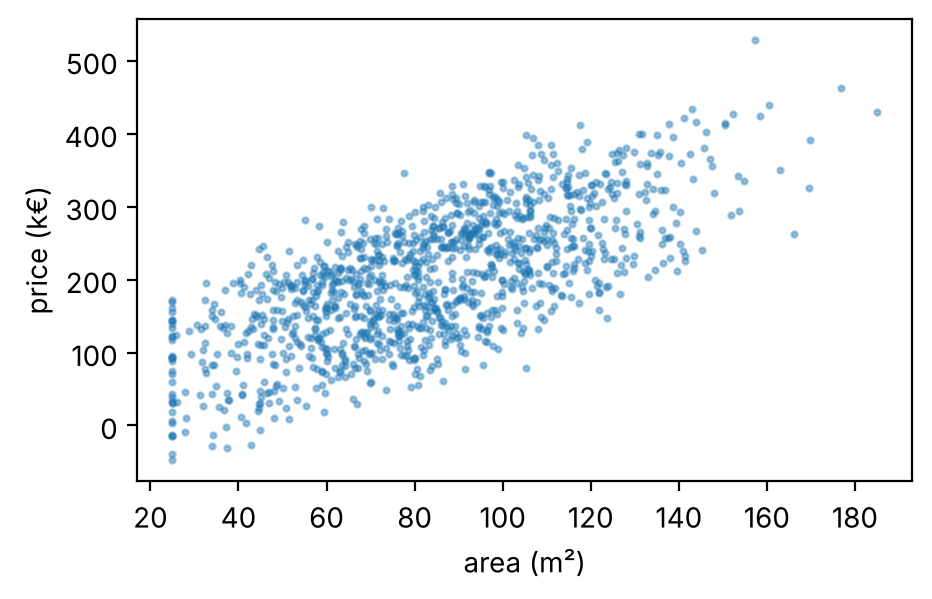

In [1]:
import sys; sys.path.insert(0, "..")
import csv
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from dnd_utils import check, DATA

# One feature and the target of houses.csv (the full parsing is the topic of notebook 04).
with open(DATA / "houses.csv", newline="") as f:
    rows = list(csv.DictReader(f))
area = np.array([float(r["area_m2"]) for r in rows], dtype=np.float32)        # square metres, roughly 25 .. 220
price = np.array([float(r["price_keur"]) for r in rows], dtype=np.float32)    # thousand EUR
print(area.shape, area.mean(), area.std(), "|", price.mean(), price.std())
plt.figure(figsize=(5, 3)); plt.scatter(area, price, s=4, alpha=.4); plt.xlabel("area (m²)"); plt.ylabel("price (k€)"); plt.show()

---
## Exercise 3.1 · The training function

Write `fit(model, X, Y, lr, steps)`: full-batch gradient descent with `nn.MSELoss` and `torch.optim.SGD`. It returns the list of losses (Python floats) measured **before** each update.

Then create the tensors `X` and `Y` from `area` and `price` with the right shapes and dtype.

In [2]:
def fit(model, X, Y, lr, steps):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    losses = []
    for _ in range(steps):
        loss = loss_fn(model(X), Y)
        losses.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return losses

X = torch.tensor(area, dtype=torch.float32).reshape(-1, 1)      # (1200, 1): n samples, 1 feature
Y = torch.tensor(price, dtype=torch.float32).reshape(-1, 1)     # (1200, 1): same shape as the model output

In [3]:
check("X shape/dtype", lambda: X.shape == (1200, 1) and X.dtype == torch.float32)
check("Y shape/dtype", lambda: Y.shape == (1200, 1) and Y.dtype == torch.float32)
torch.manual_seed(0)
check("fit returns `steps` floats", lambda: len(fit(nn.Linear(1, 1), X / 100, Y / 100, 0.1, 7)) == 7)
check("fit decreases the loss", lambda: (lambda l: l[-1] < l[0])(fit(nn.Linear(1, 1), X / 100, Y / 100, 0.1, 50)))

✅ X shape/dtype
✅ Y shape/dtype


✅ fit returns `steps` floats
✅ fit decreases the loss


True

---
## Exercise 3.2 · Watch it explode

Run the cell. The learning rate `0.1` was perfectly fine in notebook 02.

In [4]:
torch.manual_seed(0)
losses = fit(nn.Linear(1, 1), X, Y, lr=0.1, steps=12)
print([f"{l:.3g}" for l in losses])

['4.89e+04', '1.1e+11', '2.69e+17', '6.58e+23', '1.61e+30', 'inf', 'inf', 'inf', 'inf', 'inf', 'inf', 'inf']


**a)** Explain in one or two sentences why the loss explodes here but did not in notebook 02 (same model, same loss, same `lr`).

**Answer.** The gradient for the weight is `2·mean(error · x)`. In notebook 02 `x` was between −2 and 2; here `x` is around 85. So the gradient (and therefore the step) is tens of times larger for the same error, and the *curvature* of the loss in the `w` direction is `2·mean(x²) ≈ 16 000`. With `lr = 0.1` each step multiplies the distance to the optimum by about `1 − 0.1·16 000 = −1600` → it overshoots further every step: divergence to `inf`, then `nan`.

**b)** For one feature and no bias, each step multiplies the error in `w` by `(1 − lr · 2·mean(x²))` (the same argument as in exercise 2.4, with curvature `2·mean(x²)` instead of `2`). Compute the largest learning rate for which the absolute value of this factor stays below 1.

In [5]:
lr_max_theory = 1.0 / float((area ** 2).mean())       # |1 - 2 lr m| < 1  <=>  lr < 1/m,  m = mean(x^2)  -> about 1.2e-4

In [6]:
print("theoretical limit:", lr_max_theory)
check("lr_max_theory", lambda: abs(lr_max_theory - 1 / float((area.astype(np.float64) ** 2).mean())) < 1e-6)
torch.manual_seed(0); check("just below the limit: still finite after 200 steps", lambda: np.isfinite(fit(nn.Linear(1, 1), X, Y, 0.95 * lr_max_theory, 200)[-1]))
torch.manual_seed(0); check("just above the limit: diverges", lambda: not np.isfinite(fit(nn.Linear(1, 1), X, Y, 1.1 * lr_max_theory, 3000)[-1]) or fit(nn.Linear(1, 1), X, Y, 1.1 * lr_max_theory, 3000)[-1] > 1e6)

theoretical limit: 0.00012776798930242545
✅ lr_max_theory
✅ just below the limit: still finite after 200 steps


✅ just above the limit: diverges


True

**c)** So use a small learning rate? Run this and look at the **bias**. The best straight line has a bias of about `+22`.

In [7]:
torch.manual_seed(0)
slow = nn.Linear(1, 1)
losses = fit(slow, X, Y, lr=1e-4, steps=2000)
print(f"loss after 2000 steps: {losses[-1]:.1f}   weight: {slow.weight.item():.3f}   bias: {slow.bias.item():.3f}")

loss after 2000 steps: 4049.9   weight: 2.377   bias: 1.497


The weight converged quickly; the bias has hardly moved from its initial value. Why? (Think about the curvature in the `b` direction, and the factor from 2.4.)

**Answer.** The curvature in the bias direction is `2` (the "input" of the bias is the constant 1). With `lr = 1e-4`, each step multiplies the bias error by `1 − 2·10⁻⁴ = 0.9998`, so it needs on the order of tens of thousands of steps. The learning rate is dictated by the steepest direction (`w`, curvature ≈ 16 000) and is then 8000× too small for the flattest direction (`b`). One learning rate cannot suit both — **unless the features are rescaled so that all directions have similar curvature.** That is exactly what standardisation does.

---
## Exercise 3.3 · Standardise, then train

Standardise the feature (population std, i.e. NumPy's default), keep `mean_x` and `std_x`, build `Xs`, and train a fresh `nn.Linear(1, 1)` with `lr = 0.1` for 100 steps.

In [8]:
mean_x = area.mean()
std_x = area.std()
Xs = torch.tensor((area - mean_x) / std_x, dtype=torch.float32).reshape(-1, 1)

torch.manual_seed(0)
line = nn.Linear(1, 1)
losses_scaled = fit(line, Xs, Y, lr=0.1, steps=100)

In [9]:
print(f"final loss {losses_scaled[-1]:.1f}   weight {line.weight.item():.2f}   bias {line.bias.item():.2f}")
check("Xs has mean 0 and std 1", lambda: abs(Xs.mean().item()) < 1e-4 and abs(Xs.std(correction=0).item() - 1) < 1e-4)
A_ = np.stack([area, np.ones_like(area)], axis=1).astype(np.float64)
best_ = ((A_ @ np.linalg.lstsq(A_, price.astype(np.float64), rcond=None)[0] - price) ** 2).mean()
check(f"reached the best possible straight line (MSE {best_:.1f})", lambda: abs(losses_scaled[-1] - best_) < 1.0)
check("bias equals the mean price (why?)", lambda: abs(line.bias.item() - price.mean()) < 0.5)

final loss 4001.8   weight 62.83   bias 202.31
✅ Xs has mean 0 and std 1
✅ reached the best possible straight line (MSE 4001.8)
✅ bias equals the mean price (why?)


True

After standardisation the learned **bias equals the mean price**. Why is that — and what does the weight (≈ 63) mean in words?

**Answer.** The standardised feature has mean 0, so for the "average house" the model predicts `w·0 + b = b`; the least-squares line always passes through the point (mean x, mean y), hence `b = mean(price)`. The weight is the price change for a **one-standard-deviation** change of area: houses that are one std (≈ 29 m²) larger cost about 63 k€ more.

---
## Exercise 3.4 · Back to the original units

The model was trained on `x' = (x − mean_x) / std_x`:  `ŷ = w'·x' + b'`. Rewrite this as `ŷ = w·x + b` in the original units (k€ per m² and k€). Derive `w` and `b` on paper.

In [10]:
# y = w' (x - m)/s + b'  =  (w'/s) x + (b' - w' m / s)
w_orig = line.weight.item() / std_x
b_orig = line.bias.item() - line.weight.item() * mean_x / std_x

In [11]:
ref_w, ref_b = np.polyfit(area.astype(np.float64), price.astype(np.float64), 1)
print(f"yours: {w_orig}, {b_orig}    closed form: {ref_w:.3f}, {ref_b:.3f}")
check("w in original units", lambda: abs(w_orig - ref_w) < 0.02)
check("b in original units", lambda: abs(b_orig - ref_b) < 1.5)

yours: 2.15275239944458, 22.516845703125    closed form: 2.153, 22.517
✅ w in original units
✅ b in original units


True

The same rule applies to new data: a house of 100 m² must go through **the same** `mean_x` and `std_x` before it is given to the model. Predict its price with `line`.

In [12]:
x_new = torch.tensor([[(100.0 - mean_x) / std_x]], dtype=torch.float32)      # shape (1, 1): one sample, one feature
with torch.no_grad():
    price_100 = line(x_new).item()

In [13]:
check("prediction for 100 m²", lambda: abs(price_100 - (ref_w * 100 + ref_b)) < 1.5)

✅ prediction for 100 m²


True

---
## Exercise 3.5 · Is the model any good? Always compare with a baseline

A loss value alone means nothing. The simplest possible "model" predicts the **mean of the training targets** for everyone.

Compute `baseline_mse`, the model's `model_mse`, and `r2 = 1 − model_mse / baseline_mse`.

In [14]:
baseline_mse = float(((price - price.mean()) ** 2).mean())          # = the variance of the target
with torch.no_grad():
    model_mse = nn.MSELoss()(line(Xs), Y).item()
r2 = 1 - model_mse / baseline_mse

In [15]:
print(f"baseline {baseline_mse:.0f}   model {model_mse:.0f}   R² {r2:.3f}   (RMSE: {baseline_mse ** .5:.0f} k€ -> {model_mse ** .5:.0f} k€)")
check("baseline MSE is the variance of the target", lambda: abs(baseline_mse - price.var()) < 1)
check("r2", lambda: abs(r2 - (1 - model_mse / price.var())) < 1e-3 and 0.3 < r2 < 0.6)

baseline 7949   model 4002   R² 0.497   (RMSE: 89 k€ -> 63 k€)
✅ baseline MSE is the variance of the target
✅ r2


True

Area alone explains roughly half of the variance. In notebook 06 an MLP with all features will do much better. Remember the pattern: **baseline → linear model → network.** If your network is not better than the baseline, something is broken.

---
## Exercise 3.6 · Logistic regression by hand (NumPy)

Two clouds of points in 2-D; class 1 is centred at (1, 1), class 0 at (−1, −1).

Implement, vectorised:

- `sigmoid(z)`
- `bce(p, y)` — mean binary cross-entropy, with `1e-12` added inside each logarithm
- `train_logreg_numpy(X, y, lr, steps)` — weights and bias start at **zero**; each step computes `p`, records the loss (before the update), then updates with the gradients from exercise 2.3 averaged over the samples: `∂L/∂w = Xᵀ(p − y)/n`, `∂L/∂b = mean(p − y)`. Returns `(w, b, losses)`.

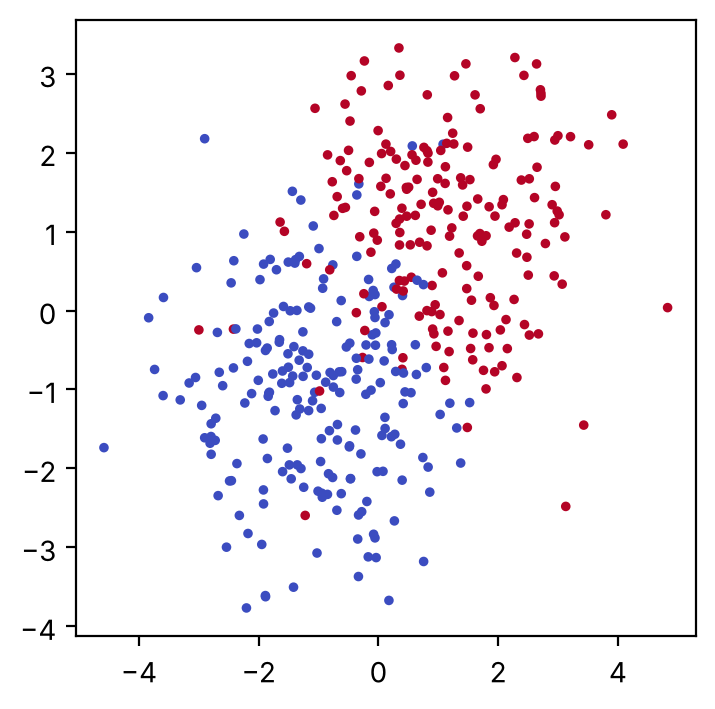

In [16]:
rng = np.random.default_rng(3)
n = 400
y2 = (rng.random(n) < 0.5).astype(np.float64)                       # (400,)
X2 = rng.normal(0, 1.2, size=(n, 2)) + np.where(y2[:, None] == 1, 1.0, -1.0)   # (400, 2)
plt.figure(figsize=(4, 4)); plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=6, cmap="coolwarm"); plt.show()

In [17]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def bce(p, y):
    return -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))

def train_logreg_numpy(X, y, lr, steps):
    n, d = X.shape
    w, b, losses = np.zeros(d), 0.0, []
    for _ in range(steps):
        p = sigmoid(X @ w + b)               # (n,)
        losses.append(bce(p, y))
        err = p - y                          # (n,)
        w -= lr * (X.T @ err) / n            # (d,n) @ (n,) -> (d,)
        b -= lr * err.mean()
    return w, b, losses

In [18]:
check("sigmoid(0) = 0.5, vectorised", lambda: np.allclose(sigmoid(np.array([0.0, 100.0, -100.0])), [0.5, 1.0, 0.0]))
check("bce of a coin-flip prediction is ln 2", lambda: abs(bce(np.full(4, 0.5), np.array([0., 1., 1., 0.])) - np.log(2)) < 1e-9)
w_np, b_np, losses_np = train_logreg_numpy(X2, y2, lr=0.5, steps=200)
check("first loss is ln 2 ≈ 0.693", lambda: abs(losses_np[0] - np.log(2)) < 1e-9)
check("loss decreases", lambda: losses_np[-1] < 0.35)
check("both weights are positive (class 1 is up-right)", lambda: (w_np > 0.5).all())

✅ sigmoid(0) = 0.5, vectorised
✅ bce of a coin-flip prediction is ln 2
✅ first loss is ln 2 ≈ 0.693
✅ loss decreases
✅ both weights are positive (class 1 is up-right)


True

Why is the very first loss exactly `ln 2 ≈ 0.693`, regardless of the data?

**Answer.** With zero weights and bias, `z = 0` for every sample, so `p = σ(0) = 0.5`. The loss of predicting 0.5 is `−ln 0.5 = ln 2` whether the label is 0 or 1. This is a great **sanity check**: an untrained binary classifier should start near 0.69 (and a k-class classifier near `ln k`). A much larger starting loss usually means unscaled inputs or a shape/label bug.

---
## Exercise 3.7 · The same thing in PyTorch

Reproduce the NumPy run with `nn.Linear(2, 1)` (weights and bias set to zero), `nn.BCEWithLogitsLoss()` and `torch.optim.SGD(lr=0.5)`, 200 full-batch steps. Record the losses before each update in `losses_torch`.

If both implementations are right, the two loss curves coincide to 4 decimals.

<details><summary>Hint — zero initialisation</summary>

```python
with torch.no_grad():
    model.weight.zero_()
    model.bias.zero_()
```
</details>

In [19]:
Xt = torch.tensor(X2, dtype=torch.float32)
yt = torch.tensor(y2, dtype=torch.float32).reshape(-1, 1)

logreg = nn.Linear(2, 1)
with torch.no_grad():
    logreg.weight.zero_()
    logreg.bias.zero_()

loss_fn = nn.BCEWithLogitsLoss()                 # takes the raw output z ("logit"), applies the sigmoid internally
optimizer = torch.optim.SGD(logreg.parameters(), lr=0.5)
losses_torch = []
for _ in range(200):
    loss = loss_fn(logreg(Xt), yt)
    losses_torch.append(loss.item())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [20]:
check("same loss curve as NumPy", lambda: len(losses_torch) == 200 and np.allclose(losses_torch, losses_np, atol=1e-4))
check("same weights as NumPy", lambda: np.allclose(logreg.weight.detach().numpy().reshape(-1), w_np, atol=1e-3))

✅ same loss curve as NumPy
✅ same weights as NumPy


True

---
## Exercise 3.8 · From logits to decisions

The model outputs a **logit** `z`. Compute, for the training points:

- `probs`: predicted probabilities of class 1, shape `(400, 1)`
- `pred`: predicted class (0.0 or 1.0) using threshold 0.5, shape `(400, 1)`
- `acc`: accuracy as a Python float
- `pred_from_logits`: the same predictions **without computing the sigmoid** (which condition on `z` is equivalent to `p > 0.5`?)

In [21]:
with torch.no_grad():
    z = logreg(Xt)
    probs = torch.sigmoid(z)
    pred = (probs > 0.5).float()
    acc = (pred == yt).float().mean().item()
    pred_from_logits = (z > 0).float()            # sigmoid(z) > 0.5  <=>  z > 0

In [22]:
check("probs in (0, 1) with shape (400, 1)", lambda: probs.shape == (400, 1) and 0 < probs.min() and probs.max() < 1)
check("accuracy is clearly better than chance", lambda: 0.85 < acc < 1.0)
check("threshold on the logit gives identical predictions", lambda: (pred_from_logits == pred).all().item())

✅ probs in (0, 1) with shape (400, 1)
✅ accuracy is clearly better than chance
✅ threshold on the logit gives identical predictions


True

The decision boundary is where `z = w₁x₁ + w₂x₂ + b = 0` — a straight line. A logistic regression can only ever separate classes with a line (a hyperplane). To bend the boundary you need hidden layers with a non-linearity: the MLP of notebook 06.

---
## Blank-page drill

From memory, in the empty cell: given `area` and `price` (NumPy, shape `(1200,)`),

1. standardise `area`,
2. build `X`, `Y` with the right shapes and dtype,
3. train `nn.Linear(1, 1)` with `MSELoss` and `SGD(lr=0.1)` for 100 full-batch steps,
4. print the final loss and the RMSE in k€.

You should land at an MSE of roughly 4 000 (RMSE ≈ 63 k€).

In [23]:
xs = (area - area.mean()) / area.std()
X_ = torch.tensor(xs, dtype=torch.float32).reshape(-1, 1)
Y_ = torch.tensor(price, dtype=torch.float32).reshape(-1, 1)
m = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
opt = torch.optim.SGD(m.parameters(), lr=0.1)
for _ in range(100):
    loss = loss_fn(m(X_), Y_)
    opt.zero_grad()
    loss.backward()
    opt.step()
print(loss.item(), loss.item() ** 0.5)

4001.7734375 63.259571904179055
